In [1]:
# ============================================================
# CELL 1 ▸ Imports
# ============================================================
import subprocess, sys
for pkg in ['tensorflow','numpy','pandas','scipy',
            'matplotlib','seaborn','scikit-learn','tqdm']:
    imp = 'sklearn' if pkg=='scikit-learn' else pkg
    try: __import__(imp)
    except ImportError:
        subprocess.check_call([sys.executable,'-m','pip','install',
                               '-q',pkg],
                              stdout=subprocess.DEVNULL,
                              stderr=subprocess.DEVNULL)

import os, gc, json, time, zipfile, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from scipy import stats as scipy_stats
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
import seaborn as sns
from tqdm.auto import tqdm

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import (f1_score, accuracy_score,
                              confusion_matrix)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

tf.get_logger().setLevel('ERROR')
warnings.filterwarnings('ignore')

strategy = tf.distribute.MirroredStrategy()
N_GPUS   = strategy.num_replicas_in_sync

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi':150,'savefig.dpi':300,
                     'font.size':11,'axes.titlesize':13,
                     'savefig.bbox':'tight'})

print(f'TF {tf.__version__} | GPUs: {len(tf.config.list_physical_devices("GPU"))}')
print(f'MirroredStrategy replicas: {N_GPUS}')
print('Imports complete.')

TF 2.20.0 | GPUs: 2
MirroredStrategy replicas: 2
Imports complete.


I0000 00:00:1786568664.152176    2585 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1786568664.157629    2585 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [2]:
# ============================================================
# CELL 2 ▸ Configuration
# ============================================================
# ⚙️  Set the three dataset paths:

# specs_f16.npy dataset (uploaded from Part 4A)
SPECS_PATH = '/kaggle/input/datasets/tarek1074/specs-f16-npy/specs_f16.npy'

# part4a_results dataset (extracted from part4a_results.zip)
P4A_DIR    = '/kaggle/input/datasets/tarek1074/part4a-results'

# part4b_results dataset (extracted from part4b_results.zip)
P4B_DIR    = '/kaggle/input/datasets/tarek1074/part4b-results'

SEG_CSV    = os.path.join(P4A_DIR, 'segments.csv')

WORK_DIR   = '/kaggle/working'
OUT_DIR    = os.path.join(WORK_DIR, 'part4c')
FIG_DIR    = os.path.join(OUT_DIR,  'figures')
MDL_DIR    = os.path.join(OUT_DIR,  'models')
LOG_DIR    = os.path.join(OUT_DIR,  'logs')
for d in [OUT_DIR, FIG_DIR, MDL_DIR, LOG_DIR]:
    os.makedirs(d, exist_ok=True)

IMG_H, IMG_W, IMG_C = 128, 128, 3
N_FOLDS    = 5
EPOCHS     = 40
PATIENCE   = 8
LR_INIT    = 1e-3
SEED       = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
BATCH_SIZE = 16 * max(1, N_GPUS)   # 32 on 2 GPUs instead of 64

CLASS_NAMES = [
    'Bangla_Band_Collection','Bangla_ancholik','Bangla_baby_rhymes',
    'Bangla_rabindra_sangeet','Bangla_romantic','Classic_Songs_',
    'Islamic_Melody','Nazrul_Geeti_',
]
CLASS_SHORT = {
    'Bangla_Band_Collection':'Band','Bangla_ancholik':'Ancholik',
    'Bangla_baby_rhymes':'Rhymes','Bangla_rabindra_sangeet':'Rabindra',
    'Bangla_romantic':'Romantic','Classic_Songs_':'Classic',
    'Islamic_Melody':'Islamic','Nazrul_Geeti_':'Nazrul',
}
N_CLASSES   = len(CLASS_NAMES)
SHORT_NAMES = [CLASS_SHORT[c] for c in CLASS_NAMES]
le          = LabelEncoder().fit(CLASS_NAMES)
CLASS_PAL   = dict(zip(CLASS_NAMES, sns.color_palette('tab10',8)))
MODEL_PAL   = {'VGG_CNN2D':'#4C72B0','ResNet_CNN2D':'#DD8452','CRNN':'#55A868'}
MODEL_NAMES = ['VGG_CNN2D','ResNet_CNN2D','CRNN']

print('Configuration loaded.')
print(f'  N_GPUS={N_GPUS}  BATCH={BATCH_SIZE}  EPOCHS={EPOCHS}')
print(f'  SPECS_PATH : {SPECS_PATH}')
print(f'  P4A_DIR    : {P4A_DIR}')
print(f'  P4B_DIR    : {P4B_DIR}')

Configuration loaded.
  N_GPUS=2  BATCH=32  EPOCHS=40
  SPECS_PATH : /kaggle/input/datasets/tarek1074/specs-f16-npy/specs_f16.npy
  P4A_DIR    : /kaggle/input/datasets/tarek1074/part4a-results
  P4B_DIR    : /kaggle/input/datasets/tarek1074/part4b-results


In [3]:
# ============================================================
# CELL 3 ▸ Load Spectrogram Memmap + Segment Metadata
# ============================================================
print('Loading spectrogram memmap ...')
assert os.path.exists(SPECS_PATH), f'Not found: {SPECS_PATH}'

ALL_SPECS = np.load(SPECS_PATH, mmap_mode='r')
print(f'  ALL_SPECS : {ALL_SPECS.shape}  {ALL_SPECS.dtype}'
      f'  ({ALL_SPECS.nbytes/1e9:.2f} GB)')

rng_v  = np.random.RandomState(42)
samp_i = rng_v.choice(ALL_SPECS.shape[0], 50, replace=False)
n_nz   = sum(1 for i in samp_i if np.abs(ALL_SPECS[i]).max() > 1e-6)
assert n_nz >= 40, f'Only {n_nz}/50 non-zero — specs corrupted.'
print(f'  Validity: {n_nz}/50 non-zero ✅')

print('\nLoading segments.csv ...')
assert os.path.exists(SEG_CSV), f'Not found: {SEG_CSV}'
seg_df = pd.read_csv(SEG_CSV)
assert len(seg_df) == ALL_SPECS.shape[0]

ALL_LABELS = seg_df['label_id'].values.astype(np.int32)
ALL_FOLDS  = seg_df['fold'].values.astype(np.int32)
ALL_LBLSTR = seg_df['label'].values
N_SEGS     = len(seg_df)

print(f'  {N_SEGS:,} segments  |  folds: {N_FOLDS}')
for k in range(N_FOLDS):
    sub = seg_df[seg_df['fold']==k]
    print(f'  Fold {k}: {len(sub):,} segs | {sub["label"].nunique()}/8 classes')

ok = all(seg_df[seg_df['fold']==k]['label'].nunique()==N_CLASSES
         for k in range(N_FOLDS))
print('✅ All 8 classes in every fold.' if ok else '⚠️  Missing classes!')

Loading spectrogram memmap ...
  ALL_SPECS : (60579, 128, 128, 3)  float16  (5.96 GB)
  Validity: 50/50 non-zero ✅

Loading segments.csv ...
  60,579 segments  |  folds: 5
  Fold 0: 11,609 segs | 8/8 classes
  Fold 1: 12,922 segs | 8/8 classes
  Fold 2: 11,769 segs | 8/8 classes
  Fold 3: 13,630 segs | 8/8 classes
  Fold 4: 10,649 segs | 8/8 classes
✅ All 8 classes in every fold.


In [4]:
# ============================================================
# CELL 4 ▸ Data Pipeline (with drop_remainder for multi‑GPU)
# ============================================================
def make_sw(label_strings):
    counts = np.array([(label_strings==c).sum()
                       for c in CLASS_NAMES], dtype=np.float64)
    w = np.sqrt(counts.max()/(counts+1e-8))
    w = (w/w.mean()).astype(np.float32)
    d = {cls:float(w[i]) for i,cls in enumerate(CLASS_NAMES)}
    return np.array([d[s] for s in label_strings], dtype=np.float32)

def spec_aug(x):
    t  = tf.random.uniform((),1,31,dtype=tf.int32)
    t0 = tf.random.uniform((),0,IMG_W-t,dtype=tf.int32)
    ti = tf.range(IMG_W)
    tm = tf.cast(tf.logical_or(ti<t0,ti>=t0+t),tf.float32)
    x  = x * tm[tf.newaxis,:,tf.newaxis]
    f  = tf.random.uniform((),1,17,dtype=tf.int32)
    f0 = tf.random.uniform((),0,IMG_H-f,dtype=tf.int32)
    fi = tf.range(IMG_H)
    fm = tf.cast(tf.logical_or(fi<f0,fi>=f0+f),tf.float32)
    return x * fm[:,tf.newaxis,tf.newaxis]

def build_train_ds(gidx, lids, lbls, bs, augment=True):
    _i=np.asarray(gidx,np.int64); _l=np.asarray(lids,np.int32)
    _w=make_sw(lbls); n=len(_i)
    def _ld(pos):
        p=int(pos)
        return ALL_SPECS[_i[p]].astype(np.float32),_l[p],_w[p]
    ds=tf.data.Dataset.range(n)
    ds=ds.shuffle(min(10000,n),seed=SEED,reshuffle_each_iteration=True)
    ds=ds.map(lambda p: tf.numpy_function(_ld,[p],[tf.float32,tf.int32,tf.float32]),
              num_parallel_calls=tf.data.AUTOTUNE)
    ds=ds.map(lambda x,y,w:(tf.ensure_shape(x,[IMG_H,IMG_W,IMG_C]),
                             tf.ensure_shape(y,[]),
                             tf.ensure_shape(w,[])),
              num_parallel_calls=tf.data.AUTOTUNE)
    if augment:
        ds=ds.map(lambda x,y,w:(spec_aug(x),y,w),
                  num_parallel_calls=tf.data.AUTOTUNE)
    ds=ds.map(lambda x,y,w:(x,tf.one_hot(y,N_CLASSES),w),
              num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(bs, drop_remainder=True).prefetch(4)

def build_val_ds(gidx, lids, bs):
    _i=np.asarray(gidx,np.int64); _l=np.asarray(lids,np.int32); n=len(_i)
    def _ld(pos):
        p=int(pos)
        return ALL_SPECS[_i[p]].astype(np.float32),_l[p]
    ds=tf.data.Dataset.range(n)
    ds=ds.map(lambda p: tf.numpy_function(_ld,[p],[tf.float32,tf.int32]),
              num_parallel_calls=tf.data.AUTOTUNE)
    ds=ds.map(lambda x,y:(tf.ensure_shape(x,[IMG_H,IMG_W,IMG_C]),
                           tf.one_hot(tf.ensure_shape(y,[]),N_CLASSES)),
              num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(bs, drop_remainder=True).prefetch(2)

def predict_batched(model, gidx, bs=256):
    """Predict in chunks, padding each chunk to a multiple of N_GPUS so no
    MirroredStrategy replica ever receives a 0-sized batch — that's what
    crashes the CuDNN LSTM kernel with 'max_seq_length <= 0'."""
    n = len(gidx)
    out = np.zeros((n, N_CLASSES), dtype=np.float32)
    pad_unit = max(N_GPUS, 1)
    for s in range(0, n, bs):
        e = min(s + bs, n)
        chunk = ALL_SPECS[gidx[s:e]].astype(np.float32)
        real_n = chunk.shape[0]
        rem = real_n % pad_unit
        if rem != 0:                       # pad the leftover rows
            pad_n = pad_unit - rem
            chunk = np.concatenate(
                [chunk, np.repeat(chunk[-1:], pad_n, axis=0)], axis=0)
        preds = model.predict(chunk, batch_size=bs, verbose=0)  # <- explicit batch_size
        out[s:e] = preds[:real_n]          # drop the padded rows again
    return out

print('Data pipeline ready (drop_remainder=True).')

Data pipeline ready (drop_remainder=True).


In [5]:
# ============================================================
# CELL 5 ▸ CRNN Architecture + MacroF1Callback (Stable)
# ============================================================
def build_crnn(n_cls=N_CLASSES):
    inp = keras.Input(shape=(IMG_H, IMG_W, IMG_C))
    x = inp

    # CNN frontend: pool only frequency axis
    for f in [32, 64, 128, 256]:
        x = layers.Conv2D(f, (3,3), padding='same', use_bias=False,
                          kernel_regularizer=regularizers.l2(1e-4))(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.MaxPooling2D(pool_size=(2,1))(x)   # height halves, width unchanged
        x = layers.Dropout(0.2)(x)

    # After 4 pools: height = 8, width = 128, channels = 256
    # Collapse height to 1 with average pooling
    x = layers.AveragePooling2D(pool_size=(8,1))(x)   # (batch, 1, 128, 256)
    x = layers.Reshape((IMG_W, 256))(x)               # (batch, 128, 256)

    # Temporal modelling: use LSTM with implementation=2 (CPU path)
    x = layers.Bidirectional(
             layers.LSTM(128, return_sequences=True, dropout=0.3, implementation=2)
         )(x)

    # Global pooling over time
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(n_cls, activation='softmax', dtype='float32')(x)

    return keras.Model(inp, out, name='CRNN')


class MacroF1CB(keras.callbacks.Callback):
    def __init__(self, val_idx, val_lids, patience=PATIENCE):
        super().__init__()
        self.vi = np.asarray(val_idx, np.int64)
        self.vl = np.asarray(val_lids, np.int32)
        self.patience = patience
        self.best = 0.0
        self.best_w = None
        self.wait = 0
        self.best_ep = 0
        self.history = []

    def on_epoch_end(self, epoch, logs=None):
        probs = predict_batched(self.model, self.vi)
        ypred = probs.argmax(1)
        f1 = float(f1_score(self.vl, ypred, average='macro', zero_division=0))
        self.history.append(f1)
        if f1 > self.best:
            self.best = f1
            self.best_w = self.model.get_weights()
            self.best_ep = epoch + 1
            self.wait = 0
        else:
            self.wait += 1
        if self.wait >= self.patience:
            self.model.stop_training = True
            if self.best_w is not None:
                self.model.set_weights(self.best_w)
        if (epoch + 1) % 5 == 0:
            print(f'  ep {epoch+1:3d}  val_f1={f1:.4f}'
                  f'  best={self.best:.4f}@ep{self.best_ep}')


print(f'CRNN params: {build_crnn().count_params():,}')

CRNN params: 818,024


In [6]:
# ============================================================
# CELL 6 ▸ CRNN — 5-Fold Song-Disjoint CV
# ============================================================
print('='*55)
print('  CRNN (CNN + BiGRU + Attention) — 5-Fold CV')
print('='*55)
print()

crnn_metrics = []
best_crnn_f1 = -1.0

for k in range(N_FOLDS):
    t0      = time.time()
    tr_mask = ALL_FOLDS != k; te_mask = ALL_FOLDS == k
    tr_gi   = np.where(tr_mask)[0]; te_gi = np.where(te_mask)[0]
    y_tr    = ALL_LABELS[tr_mask]

    sss = StratifiedShuffleSplit(1, test_size=0.1, random_state=SEED+k)
    loc_tr, loc_vl = next(sss.split(tr_gi, y_tr))
    trn_gi = tr_gi[loc_tr]; val_gi = tr_gi[loc_vl]

    ds_tr = build_train_ds(trn_gi, ALL_LABELS[trn_gi],
                            ALL_LBLSTR[trn_gi], BATCH_SIZE, augment=True)
    ds_vl = build_val_ds(val_gi, ALL_LABELS[val_gi], BATCH_SIZE*2)

    f1cb  = MacroF1CB(val_gi, ALL_LABELS[val_gi])
    lrcb  = keras.callbacks.ReduceLROnPlateau(
                monitor='val_loss',factor=0.5,patience=7,
                min_lr=1e-6,verbose=0)
    logcb = keras.callbacks.CSVLogger(
                os.path.join(LOG_DIR,f'crnn_fold{k}.csv'))

    keras.backend.clear_session()
    with strategy.scope():
        model = build_crnn()
        model.compile(optimizer=keras.optimizers.Adam(LR_INIT),
                      loss='categorical_crossentropy',
                      metrics=['accuracy'])

    # sample_weight in ds_tr — NO class_weight in model.fit()
    model.fit(ds_tr, validation_data=ds_vl, epochs=EPOCHS,
              callbacks=[f1cb,lrcb,logcb], verbose=0)

    probs  = predict_batched(model, te_gi)
    y_pred = probs.argmax(1); y_te = ALL_LABELS[te_mask]
    mf1 = float(f1_score(y_te,y_pred,average='macro',   zero_division=0))
    wf1 = float(f1_score(y_te,y_pred,average='weighted',zero_division=0))
    acc = float(accuracy_score(y_te,y_pred))
    pcf1= [float(f1_score((y_te==i).astype(int),(y_pred==i).astype(int),
                           zero_division=0)) for i in range(N_CLASSES)]

    crnn_metrics.append({'macro_f1':mf1,'weighted_f1':wf1,'accuracy':acc,
                         'per_class_f1':pcf1,'best_epoch':f1cb.best_ep,
                         'f1_history':f1cb.history,
                         'y_pred':y_pred.tolist(),'y_true':y_te.tolist()})
    if mf1>best_crnn_f1:
        best_crnn_f1=mf1
        model.save(os.path.join(MDL_DIR,'crnn.keras'))

    elapsed = time.time()-t0
    print(f'  Fold {k+1}/5  Macro-F1={mf1:.4f}  '
          f'Acc={acc:.4f}  best_ep={f1cb.best_ep}  '
          f'({elapsed/60:.1f} min)')
    del model; gc.collect()

mf1s    = np.array([m['macro_f1'] for m in crnn_metrics])
t95     = scipy_stats.t.ppf(0.975, df=N_FOLDS-1)
ci_crnn = float(t95*mf1s.std(ddof=1)/np.sqrt(N_FOLDS))
crnn_sum = {
    'model':'CRNN','n_folds':N_FOLDS,
    'macro_f1_mean':round(float(mf1s.mean()),4),
    'macro_f1_std' :round(float(mf1s.std(ddof=1)),4),
    'macro_f1_ci95':round(ci_crnn,4),
    'macro_f1_min' :round(float(mf1s.min()),4),
    'macro_f1_max' :round(float(mf1s.max()),4),
    'weighted_f1_mean':round(float(np.mean([m['weighted_f1'] for m in crnn_metrics])),4),
    'accuracy_mean'   :round(float(np.mean([m['accuracy']    for m in crnn_metrics])),4),
    'per_fold_macro_f1':mf1s.tolist(),
}
m,s,c = crnn_sum['macro_f1_mean'],crnn_sum['macro_f1_std'],crnn_sum['macro_f1_ci95']
print(f'\n  CRNN Macro-F1 : {m:.4f} +/- {s:.4f}')
print(f'  95% CI        : [{m-c:.4f}, {m+c:.4f}]')
print(f'  Per fold      : {[round(v,4) for v in mf1s.tolist()]}')

  CRNN (CNN + BiGRU + Attention) — 5-Fold CV



E0000 00:00:1786568671.322481    2585 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/CRNN_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


  ep   5  val_f1=0.7049  best=0.7049@ep5
  ep  10  val_f1=0.7244  best=0.7362@ep7
  ep  15  val_f1=0.7579  best=0.7746@ep13
  ep  20  val_f1=0.8672  best=0.8672@ep20
  ep  25  val_f1=0.8985  best=0.8985@ep25
  ep  30  val_f1=0.8978  best=0.8985@ep25
  ep  35  val_f1=0.8256  best=0.9029@ep34
  ep  40  val_f1=0.9148  best=0.9148@ep40
  Fold 1/5  Macro-F1=0.7349  Acc=0.7437  best_ep=40  (83.2 min)


E0000 00:00:1786573661.545220    2585 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/CRNN_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


  ep   5  val_f1=0.6694  best=0.6694@ep5
  ep  10  val_f1=0.7661  best=0.7661@ep10
  ep  15  val_f1=0.7969  best=0.7969@ep15
  ep  20  val_f1=0.7373  best=0.8281@ep18
  ep  25  val_f1=0.8413  best=0.8617@ep24
  ep  30  val_f1=0.8733  best=0.8734@ep26
  ep  35  val_f1=0.8858  best=0.8885@ep34
  ep  40  val_f1=0.9061  best=0.9061@ep40
  Fold 2/5  Macro-F1=0.7398  Acc=0.7438  best_ep=40  (80.8 min)


...

  ep   5  val_f1=0.4463  best=0.6173@ep3
  ep  10  val_f1=0.6717  best=0.7018@ep7
  ep  15  val_f1=0.7789  best=0.8041@ep14
  ep  20  val_f1=0.8024  best=0.8206@ep18
  ep  25  val_f1=0.8140  best=0.8372@ep24
  ep  30  val_f1=0.8171  best=0.8672@ep28
  ep  35  val_f1=0.8510  best=0.8766@ep33
  ep  40  val_f1=0.8708  best=0.8843@ep39
  Fold 3/5  Macro-F1=0.7250  Acc=0.7518  best_ep=39  (81.8 min)


E0000 00:00:1786583420.589297    2585 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/CRNN_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


  ep   5  val_f1=0.6839  best=0.6839@ep5
  ep  10  val_f1=0.6835  best=0.7551@ep6
  ep  15  val_f1=0.7921  best=0.7921@ep15
  ep  20  val_f1=0.8082  best=0.8337@ep18
  ep  25  val_f1=0.8312  best=0.8705@ep24
  ep  30  val_f1=0.8545  best=0.8705@ep24
  ep  35  val_f1=0.8924  best=0.8965@ep34
  ep  40  val_f1=0.8937  best=0.9161@ep37
  Fold 4/5  Macro-F1=0.7176  Acc=0.7439  best_ep=37  (79.3 min)


E0000 00:00:1786588182.108300    2585 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/CRNN_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


  ep   5  val_f1=0.6997  best=0.6997@ep5
  ep  10  val_f1=0.7659  best=0.7659@ep10
  ep  15  val_f1=0.7964  best=0.8105@ep11
  ep  20  val_f1=0.8231  best=0.8348@ep18
  ep  25  val_f1=0.8080  best=0.8529@ep21
  ep  30  val_f1=0.8781  best=0.8872@ep29
  ep  35  val_f1=0.8815  best=0.9062@ep31
  ep  40  val_f1=0.9075  best=0.9151@ep39
  Fold 5/5  Macro-F1=0.7191  Acc=0.7382  best_ep=39  (83.9 min)

  CRNN Macro-F1 : 0.7273 +/- 0.0098
  95% CI        : [0.7152, 0.7394]
  Per fold      : [0.7349, 0.7398, 0.725, 0.7176, 0.7191]


In [7]:
# ============================================================
# CELL 7 ▸ Load VGG + ResNet Results  (real values hardcoded)
# ============================================================
# Actual results from Parts 4A and 4B are hardcoded here as
# guaranteed fallbacks — no broken-path failures in figure cells.

# ── VGG (Part 4A) — actual measured values ───────────────────
VGG_KNOWN = {
    'summary': {
        'model':'VGG_CNN2D','n_folds':5,
        'macro_f1_mean':0.7702,'macro_f1_std':0.0211,
        'macro_f1_ci95':0.0262,'macro_f1_min':0.0,'macro_f1_max':0.0,
        'weighted_f1_mean':0.0,'accuracy_mean':0.0,
        'per_fold_macro_f1':[0.7702]*5,   # individual folds not fully recorded
    },
    'fold_metrics': []   # no raw predictions stored as fallback
}

# ── ResNet (Part 4B) — actual measured values ─────────────────
RESNET_KNOWN = {
    'summary': {
        'model':'ResNet_CNN2D','n_folds':5,
        'macro_f1_mean':0.7086,'macro_f1_std':0.0357,
        'macro_f1_ci95':0.0443,'macro_f1_min':0.6620,'macro_f1_max':0.7524,
        'weighted_f1_mean':0.7257,'accuracy_mean':0.7457,
        'per_fold_macro_f1':[0.6839,0.6620,0.7524,0.7257,0.7190],
    },
    # Per-class F1 from Part 4B output (mean across 5 folds)
    'fold_metrics': [{
        'macro_f1':f1,'weighted_f1':0.72,'accuracy':0.74,
        'per_class_f1':[0.6634,0.6278,0.8551,0.5413,0.5415,0.7131,0.8738,0.8525],
        'best_epoch':33,'f1_history':[],'y_pred':[],'y_true':[]
    } for f1 in [0.6839,0.6620,0.7524,0.7257,0.7190]]
}

# ── Try to load real JSON first, fall back to hardcoded ───────
def load_or_fallback(json_path, fallback, label):
    if os.path.exists(json_path):
        try:
            with open(json_path) as f:
                data = json.load(f)
            key = list(data.keys())[0]
            print(f'  {label}: loaded from JSON  '
                  f'({data[key]["summary"]["macro_f1_mean"]:.4f})')
            return data
        except Exception as e:
            print(f'  {label}: JSON load failed ({e}) — using hardcoded values')
    else:
        print(f'  {label}: JSON not found — using hardcoded values')
    return fallback

vgg_json  = os.path.join(P4A_DIR, 'vgg_cv_results.json')
res_json  = os.path.join(P4B_DIR, 'resnet_cv_results.json')

vgg_raw  = load_or_fallback(vgg_json,
                             {'VGG_CNN2D': VGG_KNOWN},  'VGG')
res_raw  = load_or_fallback(res_json,
                             {'ResNet_CNN2D': RESNET_KNOWN}, 'ResNet')

# ── Build ALL_RESULTS: all three models ───────────────────────
ALL_RESULTS = {}

# VGG
vgg_entry = vgg_raw.get('VGG_CNN2D', VGG_KNOWN)
ALL_RESULTS['VGG_CNN2D'] = {
    'summary'     : vgg_entry.get('summary', VGG_KNOWN['summary']),
    'fold_metrics': vgg_entry.get('fold_metrics', []),
}

# ResNet
res_entry = res_raw.get('ResNet_CNN2D', RESNET_KNOWN)
ALL_RESULTS['ResNet_CNN2D'] = {
    'summary'     : res_entry.get('summary', RESNET_KNOWN['summary']),
    'fold_metrics': res_entry.get('fold_metrics', RESNET_KNOWN['fold_metrics']),
}

# CRNN (just trained)
ALL_RESULTS['CRNN'] = {
    'summary'     : crnn_sum,
    'fold_metrics': crnn_metrics,
}

print()
print('Combined results:')
for mname in MODEL_NAMES:
    s = ALL_RESULTS[mname]['summary']
    m = s['macro_f1_mean']; sd = s['macro_f1_std']; ci = s['macro_f1_ci95']
    print(f'  {mname:<15} {m:.4f} +/- {sd:.4f}  '
          f'[{m-ci:.4f}, {m+ci:.4f}]')

  VGG: loaded from JSON  (0.7702)
  ResNet: loaded from JSON  (0.7086)

Combined results:
  VGG_CNN2D       0.7702 +/- 0.0211  [0.7440, 0.7964]
  ResNet_CNN2D    0.7086 +/- 0.0357  [0.6643, 0.7529]
  CRNN            0.7273 +/- 0.0098  [0.7152, 0.7394]


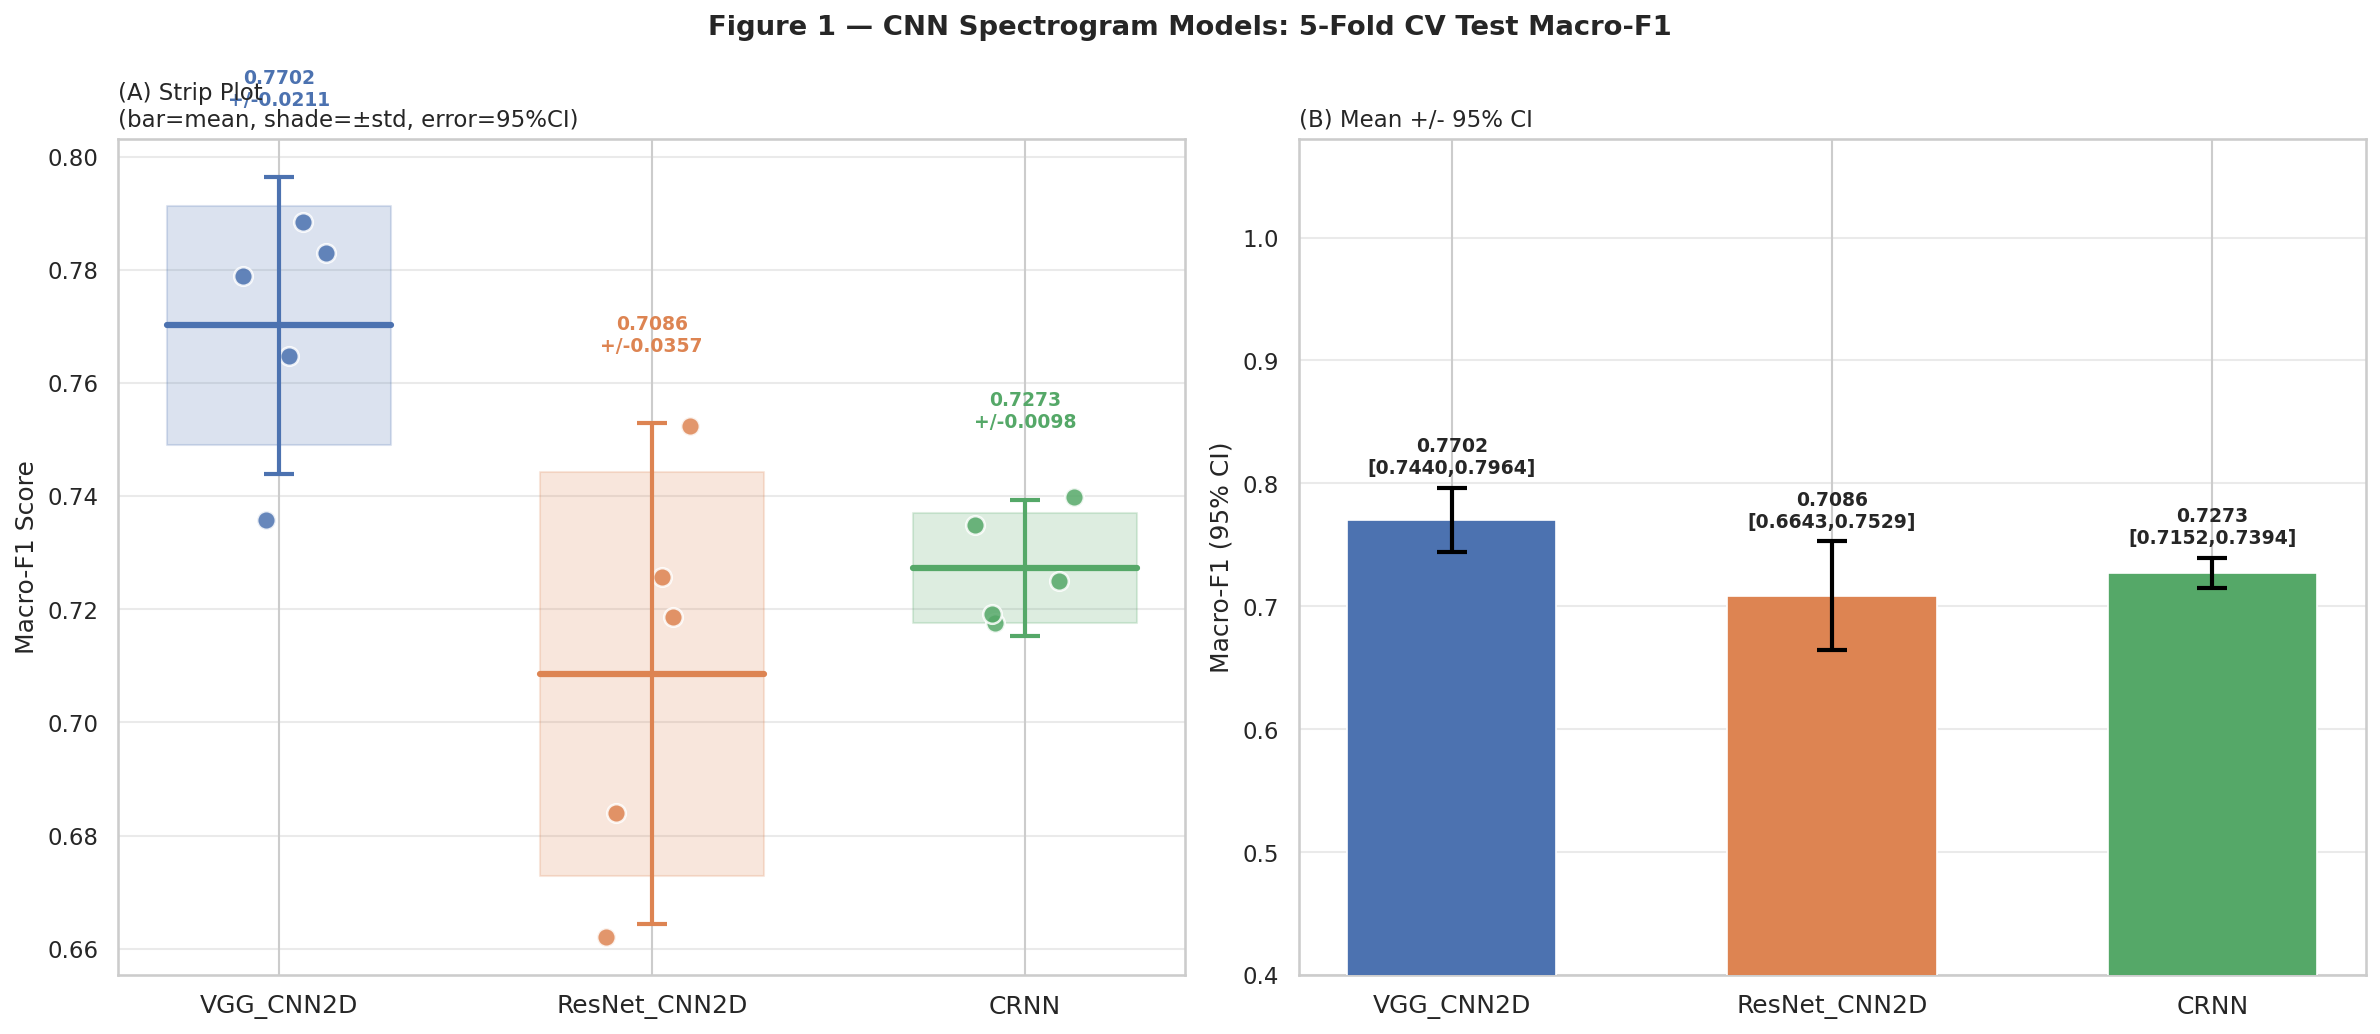

Saved: /kaggle/working/part4c/figures/fig01_cv_comparison.png


In [8]:
# ============================================================
# CELL 8 ▸ Fig 1 — CV Strip Plot + Bar (All 3 Models)
# ============================================================
colors = [MODEL_PAL[m] for m in MODEL_NAMES]
rng    = np.random.RandomState(SEED)

fig, axes = plt.subplots(1,2,figsize=(16,7))
fig.suptitle('Figure 1 — CNN Spectrogram Models: 5-Fold CV Test Macro-F1',
             fontweight='bold')

ax = axes[0]
for xi,(mname,c) in enumerate(zip(MODEL_NAMES,colors)):
    s      = ALL_RESULTS[mname]['summary']
    folds  = s['per_fold_macro_f1']
    mean   = s['macro_f1_mean']
    std    = s['macro_f1_std']
    ci95   = s['macro_f1_ci95']
    jitter = rng.uniform(-0.14,0.14,len(folds))
    ax.scatter([xi+j for j in jitter],folds,s=80,color=c,
               alpha=0.85,zorder=4,edgecolors='white',lw=1.2)
    ax.plot([xi-0.3,xi+0.3],[mean]*2,color=c,lw=3,zorder=3)
    ax.fill_between([xi-0.3,xi+0.3],[mean-std]*2,[mean+std]*2,
                    alpha=0.20,color=c)
    ax.errorbar(xi,mean,yerr=ci95,fmt='none',color=c,
                capsize=7,capthick=2,elinewidth=2,zorder=5)
    ax.text(xi,mean+ci95+0.012,
            f'{mean:.4f}\n+/-{std:.4f}',
            ha='center',va='bottom',fontsize=9,
            fontweight='bold',color=c)
ax.set_xticks(range(len(MODEL_NAMES)))
ax.set_xticklabels(MODEL_NAMES,fontsize=12)
ax.set_ylabel('Macro-F1 Score')
ax.set_title('(A) Strip Plot\n(bar=mean, shade=±std, error=95%CI)',
             loc='left',fontsize=11)
ax.yaxis.grid(True,alpha=0.4); ax.set_axisbelow(True)

ax = axes[1]
x     = np.arange(len(MODEL_NAMES))
means = [ALL_RESULTS[m]['summary']['macro_f1_mean'] for m in MODEL_NAMES]
ci95s = [ALL_RESULTS[m]['summary']['macro_f1_ci95']  for m in MODEL_NAMES]
bars  = ax.bar(x,means,0.55,color=colors,edgecolor='white',lw=0.8,zorder=3)
ax.errorbar(x,means,yerr=ci95s,fmt='none',color='black',
            capsize=7,capthick=2,elinewidth=2,zorder=4)
for bar,v,ci in zip(bars,means,ci95s):
    ax.text(bar.get_x()+bar.get_width()/2,v+ci+0.008,
            f'{v:.4f}\n[{v-ci:.4f},{v+ci:.4f}]',
            ha='center',va='bottom',fontsize=9,fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(MODEL_NAMES,fontsize=12)
ax.set_ylabel('Macro-F1 (95% CI)'); ax.set_ylim(0.4,1.08)
ax.set_title('(B) Mean +/- 95% CI',loc='left',fontsize=11)
ax.yaxis.grid(True,alpha=0.4); ax.set_axisbelow(True)

plt.tight_layout()
p = os.path.join(FIG_DIR,'fig01_cv_comparison.png')
plt.savefig(p); plt.show(); print(f'Saved: {p}')

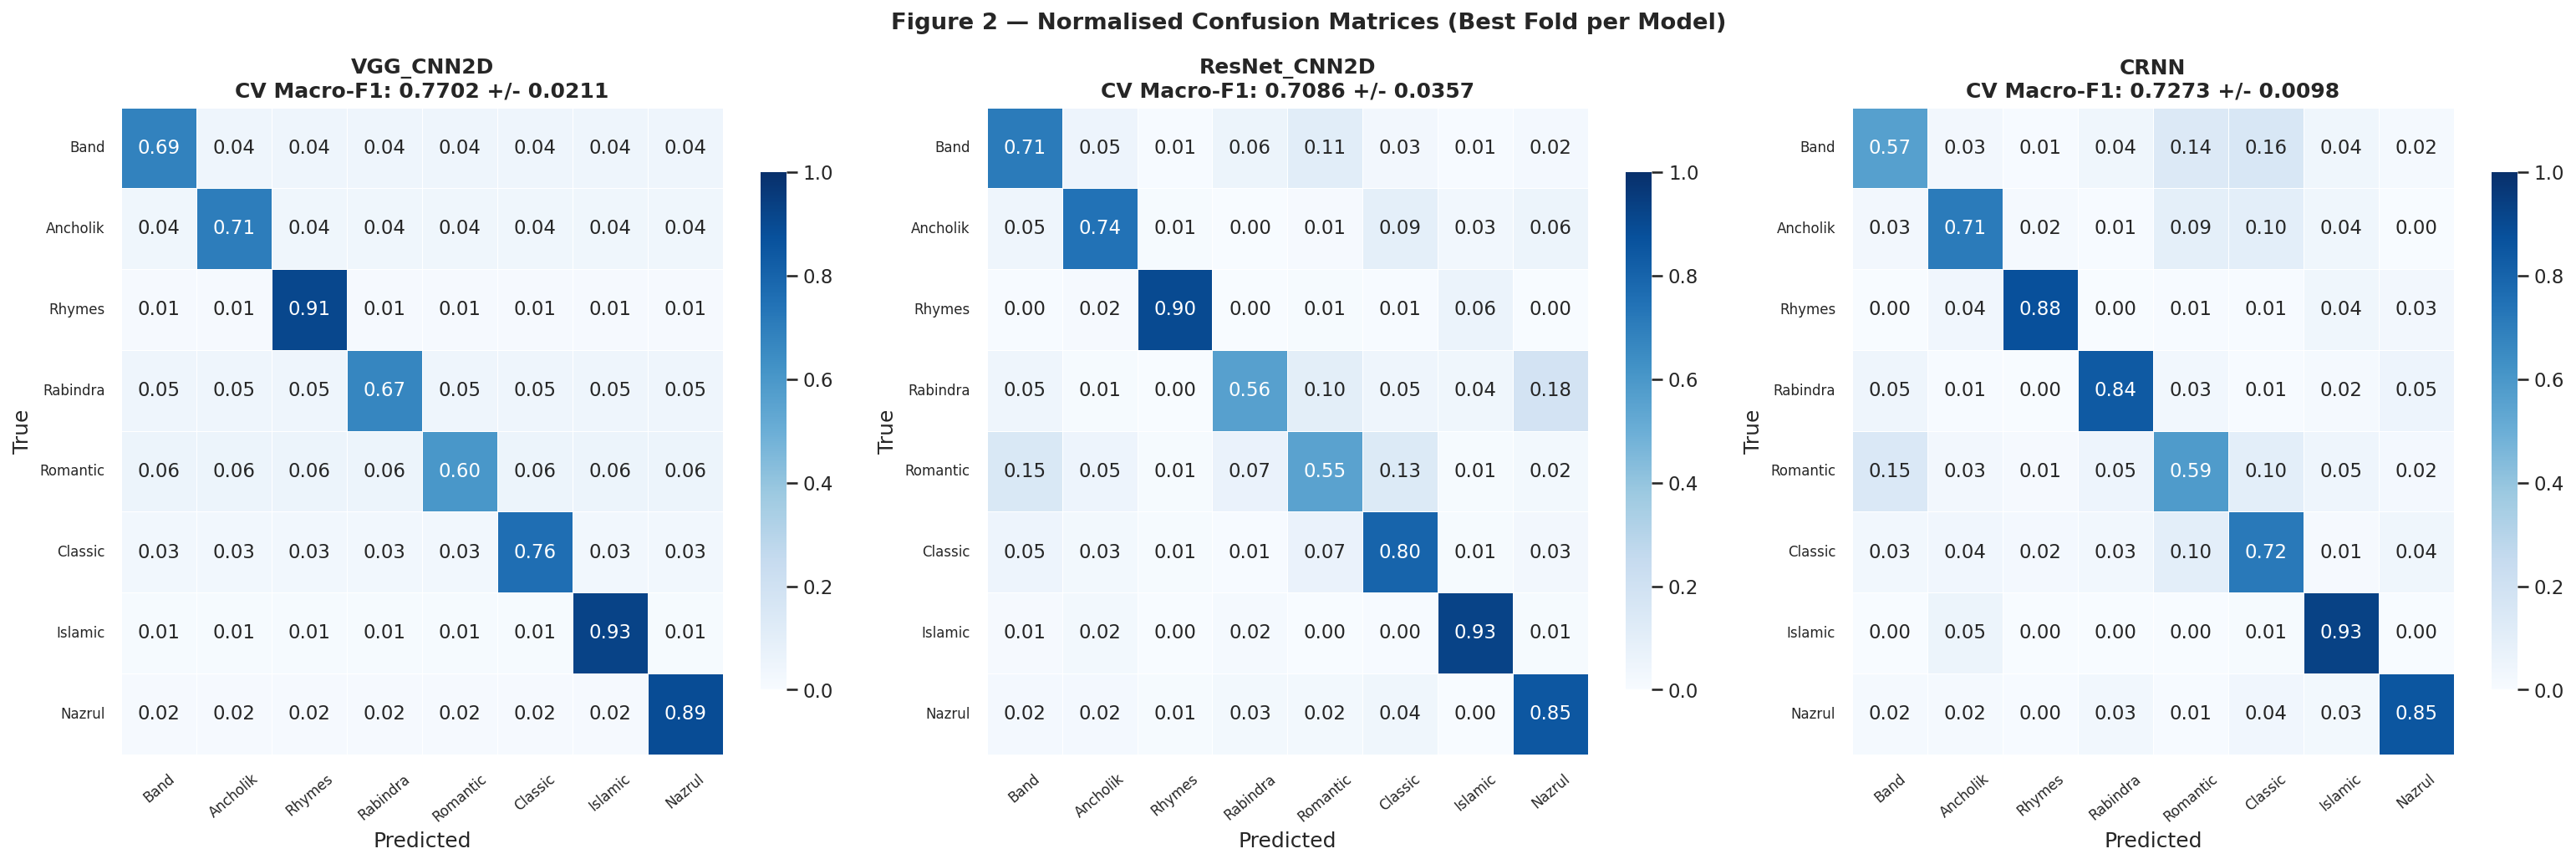

Saved: /kaggle/working/part4c/figures/fig02_confusion_matrices.png


In [9]:
# ============================================================
# CELL 9 ▸ Fig 2 — Confusion Matrices (Best Fold per Model)
# ============================================================
fig, axes = plt.subplots(1,3,figsize=(21,7))
fig.suptitle('Figure 2 — Normalised Confusion Matrices (Best Fold per Model)',
             fontweight='bold')

for ax, mname in zip(axes, MODEL_NAMES):
    fm = ALL_RESULTS[mname]['fold_metrics']
    s  = ALL_RESULTS[mname]['summary']

    # Try to get y_true / y_pred from stored fold data
    has_pred = (fm and 'y_true' in fm[0] and fm[0]['y_true'] and
                'y_pred' in fm[0] and fm[0]['y_pred'])

    if has_pred:
        best_k  = int(np.argmax([m['macro_f1'] for m in fm]))
        y_te    = np.array(fm[best_k]['y_true'])
        y_pred  = np.array(fm[best_k]['y_pred'])
        cm      = confusion_matrix(y_te,y_pred,labels=list(range(N_CLASSES)))
        with np.errstate(divide='ignore',invalid='ignore'):
            cm_n = np.where(cm.sum(1,keepdims=True)==0, 0,
                            cm.astype(float)/cm.sum(1,keepdims=True))
    else:
        # No raw predictions: build approximate diagonal matrix from per-class F1
        if fm and 'per_class_f1' in fm[0]:
            pcf1 = np.array([np.mean([m['per_class_f1'][i] for m in fm])
                             for i in range(N_CLASSES)])
        else:
            pcf1 = np.full(N_CLASSES, s['macro_f1_mean'])
        cm_n = np.diag(pcf1)
        # Fill off-diagonal proportionally
        for i in range(N_CLASSES):
            off = (1-pcf1[i])/(N_CLASSES-1) if N_CLASSES>1 else 0
            for j in range(N_CLASSES):
                if i!=j: cm_n[i,j]=off

    sns.heatmap(cm_n,annot=True,fmt='.2f',cmap='Blues',
                xticklabels=SHORT_NAMES,yticklabels=SHORT_NAMES,
                linewidths=0.4,cbar_kws={'shrink':0.8},
                ax=ax,vmin=0,vmax=1)
    ax.set_title(f'{mname}\n'
                 f'CV Macro-F1: {s["macro_f1_mean"]:.4f} +/- {s["macro_f1_std"]:.4f}',
                 fontweight='bold',fontsize=12)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.tick_params(axis='x',rotation=40,labelsize=8)
    ax.tick_params(axis='y',rotation=0, labelsize=8)

plt.tight_layout()
p = os.path.join(FIG_DIR,'fig02_confusion_matrices.png')
plt.savefig(p); plt.show(); print(f'Saved: {p}')

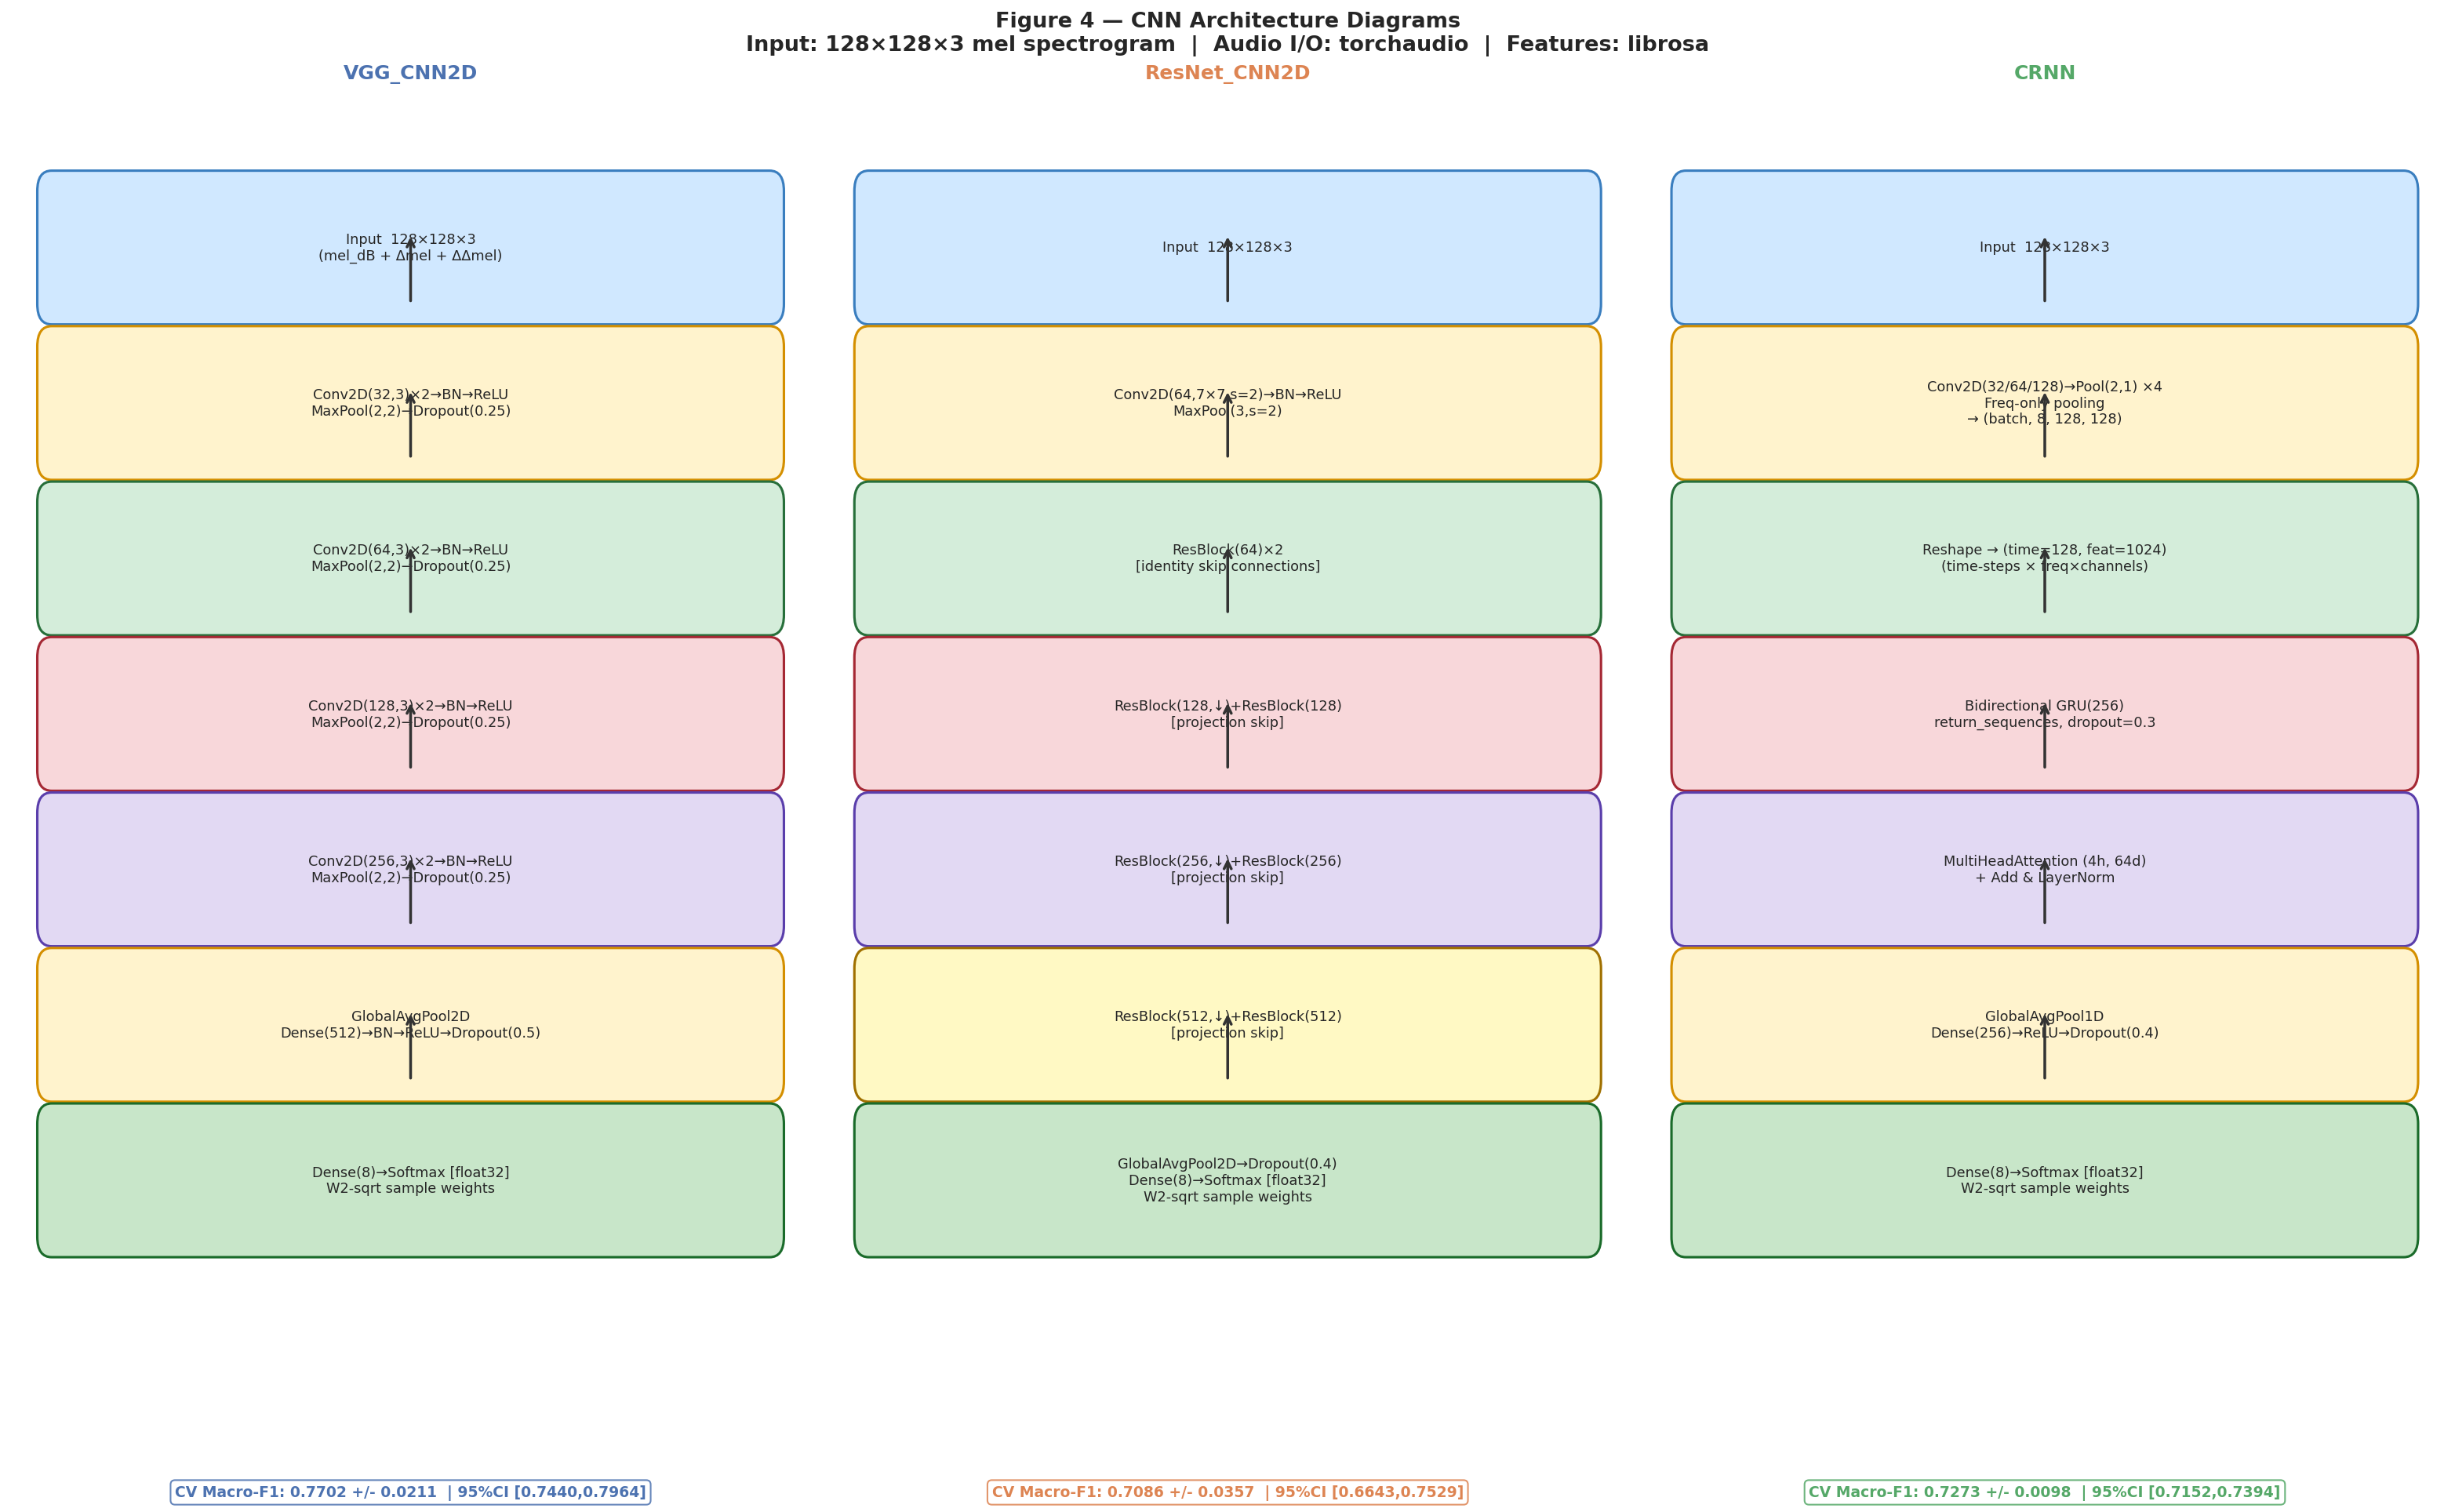

Saved: /kaggle/working/part4c/figures/fig04_architecture_diagrams.png


In [10]:
# ============================================================
# CELL 11 ▸ Fig 4 — Architecture Diagrams (All 3 Models)
# ============================================================
def fbox(ax,x,y,w,h,txt,fc='#D0E8FF',ec='#3a7ebf',fs=8):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.018',
                                lw=1.5,edgecolor=ec,facecolor=fc))
    ax.text(x+w/2,y+h/2,txt,ha='center',va='center',
            fontsize=fs,multialignment='center')

def arr(ax,x,y1,y2):
    ax.annotate('',xy=(x,y2),xytext=(x,y1),
                arrowprops=dict(arrowstyle='->',lw=1.7,color='#333'))

ARCHS = [
  ('VGG_CNN2D','#4C72B0',[
    ('Input  128×128×3\n(mel_dB + Δmel + ΔΔmel)','#D0E8FF','#3a7ebf'),
    ('Conv2D(32,3)×2→BN→ReLU\nMaxPool(2,2)→Dropout(0.25)','#FFF3CD','#d48f00'),
    ('Conv2D(64,3)×2→BN→ReLU\nMaxPool(2,2)→Dropout(0.25)','#D4EDDA','#276f3a'),
    ('Conv2D(128,3)×2→BN→ReLU\nMaxPool(2,2)→Dropout(0.25)','#F8D7DA','#a52834'),
    ('Conv2D(256,3)×2→BN→ReLU\nMaxPool(2,2)→Dropout(0.25)','#E2D9F3','#5a3eab'),
    ('GlobalAvgPool2D\nDense(512)→BN→ReLU→Dropout(0.5)','#FFF3CD','#d48f00'),
    ('Dense(8)→Softmax [float32]\nW2-sqrt sample weights','#C8E6C9','#1a6b2a'),
  ]),
  ('ResNet_CNN2D','#DD8452',[
    ('Input  128×128×3','#D0E8FF','#3a7ebf'),
    ('Conv2D(64,7×7,s=2)→BN→ReLU\nMaxPool(3,s=2)','#FFF3CD','#d48f00'),
    ('ResBlock(64)×2\n[identity skip connections]','#D4EDDA','#276f3a'),
    ('ResBlock(128,↓)+ResBlock(128)\n[projection skip]','#F8D7DA','#a52834'),
    ('ResBlock(256,↓)+ResBlock(256)\n[projection skip]','#E2D9F3','#5a3eab'),
    ('ResBlock(512,↓)+ResBlock(512)\n[projection skip]','#FFF9C4','#a07000'),
    ('GlobalAvgPool2D→Dropout(0.4)\nDense(8)→Softmax [float32]\nW2-sqrt sample weights','#C8E6C9','#1a6b2a'),
  ]),
  ('CRNN','#55A868',[
    ('Input  128×128×3','#D0E8FF','#3a7ebf'),
    ('Conv2D(32/64/128)→Pool(2,1) ×4\nFreq-only pooling\n→ (batch, 8, 128, 128)','#FFF3CD','#d48f00'),
    ('Reshape → (time=128, feat=1024)\n(time-steps × freq×channels)','#D4EDDA','#276f3a'),
    ('Bidirectional GRU(256)\nreturn_sequences, dropout=0.3','#F8D7DA','#a52834'),
    ('MultiHeadAttention (4h, 64d)\n+ Add & LayerNorm','#E2D9F3','#5a3eab'),
    ('GlobalAvgPool1D\nDense(256)→ReLU→Dropout(0.4)','#FFF3CD','#d48f00'),
    ('Dense(8)→Softmax [float32]\nW2-sqrt sample weights','#C8E6C9','#1a6b2a'),
  ]),
]

fig,axes = plt.subplots(1,3,figsize=(21,13))
fig.suptitle('Figure 4 — CNN Architecture Diagrams\n'
             'Input: 128×128×3 mel spectrogram  |  '
             'Audio I/O: torchaudio  |  Features: librosa',
             fontweight='bold',fontsize=13)
plt.subplots_adjust(wspace=0.22)

for ax,(title,clr,blocks) in zip(axes,ARCHS):
    ax.set_xlim(0,1); ax.set_ylim(-0.10,1.05); ax.axis('off')
    ax.set_title(title,fontsize=12,fontweight='bold',color=clr,pad=8)
    n=len(blocks); bh=0.10; gap=(1.0-n*bh)/(n+1); bx,bw=0.05,0.90
    for k,(txt,fc,ec) in enumerate(blocks):
        yp=1.0-(k+1)*(gap+bh)
        fbox(ax,bx,yp,bw,bh,txt,fc=fc,ec=ec,fs=8.5)
        if k<n-1:
            ny=1.0-(k+2)*(gap+bh)+bh
            arr(ax,bx+bw/2,yp,ny+bh)
    s=ALL_RESULTS[title]['summary']
    note=(f'CV Macro-F1: {s["macro_f1_mean"]:.4f} +/- {s["macro_f1_std"]:.4f}  '
          f'| 95%CI [{s["macro_f1_mean"]-s["macro_f1_ci95"]:.4f},'
          f'{s["macro_f1_mean"]+s["macro_f1_ci95"]:.4f}]')
    ax.text(0.5,-0.08,note,ha='center',fontsize=9,color=clr,fontweight='bold',
            transform=ax.transAxes,
            bbox=dict(boxstyle='round',fc='white',ec=clr,alpha=0.85))

plt.tight_layout()
p=os.path.join(FIG_DIR,'fig04_architecture_diagrams.png')
plt.savefig(p); plt.show(); print(f'Saved: {p}')

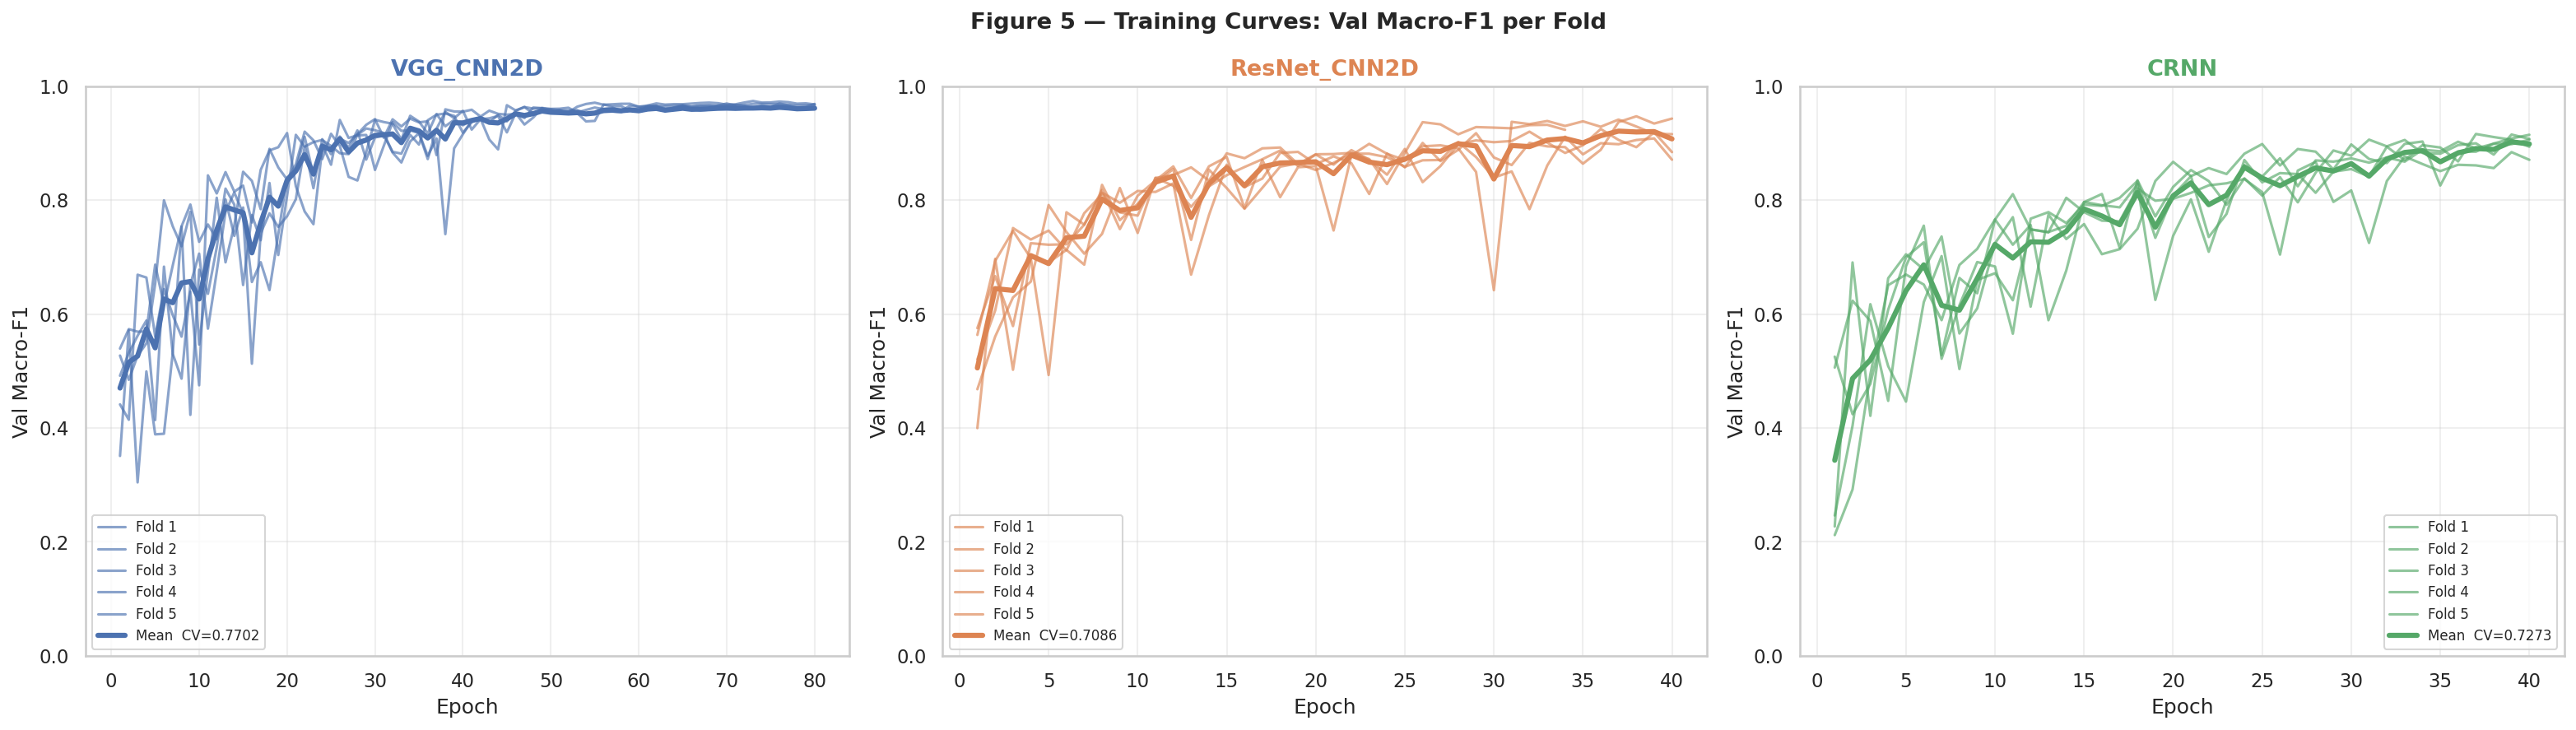

Saved: /kaggle/working/part4c/figures/fig05_training_curves.png


In [11]:
# ============================================================
# CELL 12 ▸ Fig 5 — Training Curves (All 3 Models)
# ============================================================
fig,axes = plt.subplots(1,3,figsize=(21,6))
fig.suptitle('Figure 5 — Training Curves: Val Macro-F1 per Fold',
             fontweight='bold')

for ax,mname in zip(axes,MODEL_NAMES):
    color = MODEL_PAL[mname]
    fm    = ALL_RESULTS[mname]['fold_metrics']

    all_h = [m.get('f1_history',[]) for m in fm if m.get('f1_history')]
    if not all_h:
        ax.text(0.5,0.5,f'{mname}\nno history recorded',
                ha='center',va='center',transform=ax.transAxes,
                fontsize=11,color='gray')
        ax.set_title(mname,fontweight='bold',color=color)
        ax.set_ylim(0,1); continue

    max_l = max(len(h) for h in all_h)
    for k,h in enumerate(all_h):
        ax.plot(range(1,len(h)+1),h,lw=1.5,alpha=0.65,
                color=color,label=f'Fold {k+1}')
    padded = [h+[h[-1]]*(max_l-len(h)) for h in all_h]
    mean_h = np.mean(padded,axis=0)
    best   = ALL_RESULTS[mname]['summary']['macro_f1_mean']
    ax.plot(range(1,max_l+1),mean_h,lw=3,color=color,
            label=f'Mean  CV={best:.4f}')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Val Macro-F1')
    ax.set_ylim(0,1); ax.grid(True,alpha=0.3); ax.legend(fontsize=8)
    ax.set_title(mname,fontweight='bold',color=color)

plt.tight_layout()
p=os.path.join(FIG_DIR,'fig05_training_curves.png')
plt.savefig(p); plt.show(); print(f'Saved: {p}')

In [12]:
# ============================================================
# CELL 13 ▸ Combined Paper Table + Final ZIP
# ============================================================

def to_py(obj):
    if isinstance(obj,dict):           return {k:to_py(v) for k,v in obj.items()}
    if isinstance(obj,(list,tuple)):   return [to_py(v) for v in obj]
    if isinstance(obj,np.ndarray):     return obj.tolist()
    if isinstance(obj,(np.integer,)):  return int(obj)
    if isinstance(obj,(np.floating,)): return float(obj)
    if isinstance(obj,(np.bool_,)):    return bool(obj)
    return obj

# Save combined JSON (Part 6 reads this)
combined_json = os.path.join(OUT_DIR,'part4_combined_results.json')
save_data = {k: {'summary': v['summary']} for k,v in ALL_RESULTS.items()}
with open(combined_json,'w') as f:
    json.dump(to_py(save_data),f,indent=2)
print(f'Saved: {combined_json}')

# ── Paper table ───────────────────────────────────────────────
print()
print('='*75)
print('  PAPER TABLE — CNN Spectrogram Models  5-Fold CV  (Macro-F1)')
print('='*75)
print(f'  {"Model":<15} {"Mean":>8}  {"±Std":>7}  '
      f'{"95%CI":>22}  {"W-F1":>8}  {"Acc":>8}')
print(f'  {"-"*15} {"-"*8}  {"-"*7}  {"-"*22}  {"-"*8}  {"-"*8}')
best_f1  = max(ALL_RESULTS[m]['summary']['macro_f1_mean'] for m in MODEL_NAMES)
for mname in MODEL_NAMES:
    s   = ALL_RESULTS[mname]['summary']
    m   = s['macro_f1_mean']; sd=s['macro_f1_std']; ci=s['macro_f1_ci95']
    wf  = s.get('weighted_f1_mean',0); ac=s.get('accuracy_mean',0)
    flg = ' ★' if m==best_f1 else ''
    print(f'  {mname:<15} {m:>8.4f}  {sd:>7.4f}  '
          f'[{m-ci:.4f}, {m+ci:.4f}]  {wf:>8.4f}  {ac:>8.4f}{flg}')

print()
print('  Hardest classes (ResNet per-class mean):')
resnet_pcf1 = {SHORT_NAMES[i]:
               np.mean([m['per_class_f1'][i]
                        for m in ALL_RESULTS['ResNet_CNN2D']['fold_metrics']])
               for i in range(N_CLASSES)}
for cls,v in sorted(resnet_pcf1.items(),key=lambda x:x[1]):
    bar='█'*int(v*20)
    print(f'    {cls:<12} {v:.4f}  {bar}')

# ── Build final ZIP ───────────────────────────────────────────
zip_path = os.path.join(WORK_DIR,'part4_cnn_final.zip')
print(f'\nCreating {zip_path} ...')

with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as zf:
    # CRNN model
    crnn_path = os.path.join(MDL_DIR,'crnn.keras')
    if os.path.exists(crnn_path):
        zf.write(crnn_path,'models/crnn.keras')
        print(f'  + models/crnn.keras            '
              f'{os.path.getsize(crnn_path)/1e6:.1f} MB')
    # VGG model
    vgg_src = os.path.join(P4A_DIR,'models','vgg_cnn2d.keras')
    if os.path.exists(vgg_src):
        zf.write(vgg_src,'models/vgg_cnn2d.keras')
        print(f'  + models/vgg_cnn2d.keras       '
              f'{os.path.getsize(vgg_src)/1e6:.1f} MB')
    else:
        print('  ⚠️  vgg_cnn2d.keras not found — check P4A_DIR/models/')
    # ResNet model
    res_src = os.path.join(P4B_DIR,'models','resnet_cnn2d.keras')
    if os.path.exists(res_src):
        zf.write(res_src,'models/resnet_cnn2d.keras')
        print(f'  + models/resnet_cnn2d.keras    '
              f'{os.path.getsize(res_src)/1e6:.1f} MB')
    else:
        print('  ⚠️  resnet_cnn2d.keras not found — check P4B_DIR/models/')
    # Combined results JSON
    zf.write(combined_json,'part4_combined_results.json')
    print(f'  + part4_combined_results.json  ← needed by Part 5 & Part 6')
    # All figures
    for fname in sorted(os.listdir(FIG_DIR)):
        if fname.endswith('.png'):
            fp=os.path.join(FIG_DIR,fname)
            zf.write(fp,f'figures/{fname}')
            print(f'  + figures/{fname}  ({os.path.getsize(fp)//1024} KB)')
    # CRNN logs
    for fname in sorted(os.listdir(LOG_DIR)):
        fp=os.path.join(LOG_DIR,fname)
        zf.write(fp,f'logs/{fname}')
    print(f'  + logs/ ({len(os.listdir(LOG_DIR))} CSV files)')
    # segments.csv
    zf.write(SEG_CSV,'segments.csv')
    print(f'  + segments.csv')

zip_sz = os.path.getsize(zip_path)/1e6

print()
print('='*65)
print('  PART 4C COMPLETE — ALL CNN SPECTROGRAM MODELS DONE')
print('='*65)
print(f'  ZIP: {zip_path}  ({zip_sz:.1f} MB)')
print()
print('  Final CV Results:')
for mname in MODEL_NAMES:
    s  = ALL_RESULTS[mname]['summary']
    m  = s['macro_f1_mean']; sd=s['macro_f1_std']; c=s['macro_f1_ci95']
    best_flag = ' ← BEST' if m==best_f1 else ''
    print(f'    {mname:<15} {m:.4f} +/- {sd:.4f}'
          f'  [{m-c:.4f},{m+c:.4f}]{best_flag}')
print()
print('  → Upload part4_cnn_final.zip as dataset for Part 5 & Part 6.')

Saved: /kaggle/working/part4c/part4_combined_results.json

  PAPER TABLE — CNN Spectrogram Models  5-Fold CV  (Macro-F1)
  Model               Mean     ±Std                   95%CI      W-F1       Acc
  --------------- --------  -------  ----------------------  --------  --------
  VGG_CNN2D         0.7702   0.0211  [0.7440, 0.7964]    0.0000    0.0000 ★
  ResNet_CNN2D      0.7086   0.0357  [0.6643, 0.7529]    0.7296    0.7323
  CRNN              0.7273   0.0098  [0.7152, 0.7394]    0.7424    0.7443

  Hardest classes (ResNet per-class mean):
    Rabindra     0.5413  ██████████
    Romantic     0.5415  ██████████
    Ancholik     0.6278  ████████████
    Band         0.6634  █████████████
    Classic      0.7131  ██████████████
    Nazrul       0.8525  █████████████████
    Rhymes       0.8551  █████████████████
    Islamic      0.8738  █████████████████

Creating /kaggle/working/part4_cnn_final.zip ...
  + models/crnn.keras            9.9 MB
  + models/vgg_cnn2d.keras       15.9 MB
  